# AFM Simulation


**This notebook provides a complete example on how to create a simulated AFM dataset.**

The section simulates a dataset 
**Output**; A simulated AFM dataset

## 1. Optional installations

Uncomment the lines if using Colab/Kaggle.

In [1]:
#!pip3 install deeplay plotly ipywidgets ipympl

# from google.colab import output
# output.enable_custom_widget_manager()

## 2. Imports and configuration

Here we import necessary libraries and scripts.

In [2]:
from __future__ import annotations

import glob
import importlib
import json
import logging
import os
import random
import sys
from copy import deepcopy
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path
from typing import Optional

import matplotlib
import matplotlib.animation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn
from IPython.display import display
from matplotlib.pylab import maximum
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

import deeplay as dl
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

torch.set_num_threads(1)

We configure our simulator and model. The user must configure the experimental parameters, sample parameters and if desired the model parameters to adapt to their experimental setup.

1. **SimulationConfig**:
    1. The user must select the scan resolution that consists of pixel number $(n_x, n_y)$ and pixel size.
    2. Force-distance curve (FDC) parameters must be defined: $z~length$, $z~speed$, sampling frequency $f_s$ and $set-point~force$.
    3. Depending on the cantilever choice the tip shape and the desired thermal noise type must be selected.
    4. Curve mode must be selected between 'approach' and 'approach-retract'. This will depend on the used contact mechanics model.
3. **DatasetConfig**:
    1. Quantity of samples for training, validating and testing must be indicated.
    2. Topography types we want to use and the height range we are expecting.
    3. Range of stiffness for the substrate and the sample must be indicated. This is only an estimation and doesn't need to be precise.
5. **ModelConfig**:
    1. This contains the parameters of the model. The user does not need to adjust these values but it can b emodified if desired.

In [3]:
SEED = 70
np.random.seed(SEED)
torch.manual_seed(SEED)

@dataclass
class SimulationConfig:
    """Configuration for AFM simulation parameters."""

    nx = 16
    ny = 16
    pixel_size_m = 2e-6
    z_length_m = 3e-6
    z_speed_um_s = 9
    sampling_frequency_hz = 3000
    setpoint_force_n_range = [1e-9, 1e-9]
    tip_shape = "Sphere" # options: "Pyramid", "Sphere"
    include_thermal_noise = True
    noise_type = "experimental" # options: "theoretical", "experimental", "rms"
    experimental_noise_path = \
      "../data/thermal-noise-data_vDeflection_2025.11.28-16.42.57.tnd"
    curve_mode = "approach" # options: "approach", "approach_retract"
    multi_modal = True # options: True, False
    range_multi_modal = "short" # options: "short", "long"

@dataclass
class DatasetConfig:
    """Configuration for dataset generation parameters."""

    n_samples = 50
    topography_types = ("gaussian_features", "hemisphere")
    substrate_stiffness_range_pa = (0.1e3, 5e3)
    feature_stiffness_range_pa = (0.1e3, 5e3)
    height_range_m = (5e-8, 2.9e-6)

@dataclass
class ModelConfig:
    """Configuration for model training parameters."""

    batch_size = 256
    learning_rate = 2e-3
    max_epochs = 3000
    predict_contact_point = True
    cp_loss_weight = 0.5
    num_workers = 0
    accelerator = "auto"
    devices = 1
    default_sample_to_display = 0


simulation_config = SimulationConfig()
dataset_config = DatasetConfig()
model_config = ModelConfig()

print(simulation_config)
print(dataset_config)
print(model_config)


SimulationConfig()
DatasetConfig()
ModelConfig()


## 3. Cantilever model with PSD


The `AFMCantilever` class represents the physical cantilever. Required inputs are: tip geometry, tip size, spring constant, resonance frequency, quality factor, and temperature — all available on the cantilever box or thermal calibration file.

The class handles two responsibilities: computing the contact area for a given indentation, and generating thermal noise. Three noise options are provided:

1. **Equipartition theorem**: The mean square displacement of the cantilever under thermal fluctuations is equal to $ k_B T / k $ under the equipartitoin theorem. In order to use this option the spring constant of the cantilever and the temperature we operate in must be known. Select 'rms' for the noise type.
   
2. **Theoretical PSD**: The cantilever behaves as a damped harmonic oscillator for which we can compute the power spectral density (PSD) that we denote as $S(f_x, f_y)$. Depending on our sampling frequency we compute a time domain noise from the theoretical PSD. Alongside the spring constant of the cantilever and the temperature, the user must also input the resonant frequency and the quality factor of the cantilever. Select 'Theoretical' for the noise type.
   
3. **Experimental PSD**: In the beginning of an AFM experiment the software measures the PSD of the cantilever in order to do thermal calibration. In this option the time domain noise is generated from the experimental PSD. Select 'Experimental' for the noise type and provide the path that leads to the '.tnd' calibration file.

In [4]:
class AFMCantilever:
    """AFM cantilever model with thermal-noise PSD support.

    This class represents the cantilever and stores parameters relevant to its
    thermal noise characteristics, allowing for both theoretical and
    experimental PSDs to be used in simulations.

    Parameters
    ----------
    k: float
        Spring constant in N/m.
    f0: float
        Resonance frequency in Hz.
    Q: float
        Quality factor.
    T: float
        Temperature in kelvin.

    Methods
    -------
    `thermal_noise_rms() -> float`
        Returns the RMS thermal deflection in meters.
    `thermal_noise_psd_theoretical(frequency_hz) -> np.ndarray`
        Returns the one-sided theoretical displacement PSD in m^2/Hz.
    `thermal_noise_psd_experimental(path) -> 
                        tuple[np.ndarray, np.ndarray, np.ndarray]`
        Loads and caches an experimental displacement PSD from a file.
    `get_noise_psd(...) -> tuple[np.ndarray, np.ndarray]`
        Returns the simulation-grid PSD based on the specified noise type.
    `sample_thermal_noise(...) -> np.ndarray`
        Draws one thermal-noise trace from the PSD and returns it in meters.

    """

    def __init__(
        self: AFMCantilever,
        k: float =0.1,
        f0: float =7e3,
        Q: float =10.0,
        T: float =300.0,
    ):
        """Initializes the AFMCantilever.

        Initializes the AFMCantilever with given parameters and computes
        derived properties.

        Parameters
        ----------
        k: float, optional
            Spring constant in N/m (default is 0.1).
        f0: float, optional
            Resonance frequency in Hz (default is 7e3).
        Q: float, optional
            Quality factor (default is 10.0).
        T: float, optional
            Temperature in kelvin (default is 300.0).

        """

        self.k = k
        self.f0 = f0
        self.Q = Q
        self.T = T
        self.kB = 1.380649e-23
        self.m_eff = k / (2.0 * np.pi * f0) ** 2
        self.gamma = 2.0 * np.pi * f0 * self.m_eff / Q
        self._experimental_psd_cache = {}
        self._grid_psd_cache = {}

    def thermal_noise_rms(
        self: AFMCantilever,
    ) -> float:
        """Return the RMS thermal deflection in meters.

        Returns
        -------
        float
            RMS thermal deflection in meters.

        """

        return np.sqrt(self.kB * self.T / self.k)

    def thermal_noise_psd_theoretical(
        self: AFMCantilever,
        frequency_hz: np.ndarray,
    ) -> np.ndarray:
        """Return the one-sided theoretical displacement PSD.

        Parameters
        ----------
        frequency_hz: np.ndarray
                Frequencies in Hz at which to evaluate the PSD.

        Returns
        -------
        np.ndarray
            PSD in m^2/Hz.

        """

        omega  = 2.0 * np.pi * frequency_hz
        omega0 = 2.0 * np.pi * self.f0
        denom  = (omega0**2 - omega**2)**2 + (omega * omega0 / self.Q)**2
        return (4.0 * self.kB * self.T * self.gamma) / (self.k**2 * denom)

    def thermal_noise_psd_experimental(
        self: AFMCantilever,
        path: str,
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Load and cache an experimental displacement PSD.

        Loads the experimental PSD from the provided path. Converts the
        displacement from volts to meters using the metadata in the file.

        Parameters
        ----------
        path: str
            Path to the experimental PSD file.

        Returns
        -------
        tuple of np.ndarray
            (frequency_hz, spectral_density_x, spectral_density_x_fit)

        """

        cache_key = str(path)
        if cache_key not in self._experimental_psd_cache:
            data = np.loadtxt(path, skiprows=24)
            frequency_hz       = data[:, 0]
            spectral_density_v = data[:, 1]
            spectral_density_v_fit = data[:, 3]
            with open(path, "r") as f:
                lines = f.readlines()
            for line in lines:
                if "sensitivity" in line:
                    volts_to_displacement_nm = \
                      float(line.split(":")[1].split()[0])
                if "parameter.f" in line:
                    self.f0 = float(line.split(":")[1].split()[0]) * 1e3
                if "parameter.Q" in line:
                    self.Q = float(line.split(":")[1].split()[0])
            scale = volts_to_displacement_nm * 1e-9
            self._experimental_psd_cache[cache_key] = (
                frequency_hz,
                spectral_density_v     * scale**2,
                spectral_density_v_fit * scale**2,
            )
        return self._experimental_psd_cache[cache_key]

    def get_noise_psd(
        self: AFMCantilever,
        n_points: int,
        sampling_frequency_hz: float,
        noise_type: str = simulation_config.noise_type,
        experimental_path: str = simulation_config.experimental_noise_path,
    ) -> tuple[np.ndarray, np.ndarray]:
        """Returns the simulation-grid PSD.

        Returns the theoretical PSD calculated with the harmonic oscillator
        model. When it's possible the cached results are reused.

        Parameters
        ----------
        n_points: int
            Number of points in the simulation grid.
        sampling_frequency_hz: float
            Sampling frequency in Hz.
        noise_type: str
            Type of noise ("theoretical", "experimental" or "rms").
        experimental_path: str or None
            Path to the experimental PSD file.

        Returns
        -------
        tuple of np.ndarray
            (frequency_hz, spectral_density_x)

        """

        cache_key = (noise_type.lower(), int(n_points), \
                     float(sampling_frequency_hz),None if experimental_path
                     is None else str(experimental_path))
        if cache_key in self._grid_psd_cache:
            return self._grid_psd_cache[cache_key]

        frequency_hz = np.fft.rfftfreq(n_points, d=1.0 / sampling_frequency_hz)
        if noise_type.lower() == "theoretical":
            spectral_density_x = \
              self.thermal_noise_psd_theoretical(frequency_hz)
        elif noise_type.lower() == "experimental":
            if experimental_path is None:
                raise ValueError("`experimental_path` must be provided for \
                experimental PSD.")
            frequency_hz, spectral_density_x, _ = (
                self.thermal_noise_psd_experimental(experimental_path)
            )
        else:
            raise ValueError(f"Unknown noise type: {noise_type}")

        self._grid_psd_cache[cache_key] = (frequency_hz, spectral_density_x)
        return self._grid_psd_cache[cache_key]

    def sample_thermal_noise(
        self: AFMCantilever,
        n_points: int,
        sampling_frequency_hz: float,
        noise_type: str = simulation_config.noise_type,
        experimental_path: str = simulation_config.experimental_noise_path,
        rng=None,
    ) -> np.ndarray:
        """Draws one thermal-noise trace from the PSD.

        Draws one trace of thermal noise from the PSD using random phase and
        converts it to time domain noise using np.fft.irfft

        Parameters
        ----------
        n_points: int
            Number of points in the simulation grid.
        sampling_frequency_hz: float
            Sampling frequency in Hz.
        noise_type: str
            Type of noise ("theoretical", "experimental" or "rms").
        experimental_path: str or None
            Path to the experimental PSD file.
        rng: numpy.random.Generator or None
            Random number generator instance. If None, a new instance is
            created.

        Returns
        -------
        np.ndarray
            Noise trace in meters, shape (n_points,).

        """

        rng = np.random.default_rng() if rng is None else rng
        frequency_hz, spectral_density_x = self.get_noise_psd(
            n_points, sampling_frequency_hz, noise_type, experimental_path
        )
        df = sampling_frequency_hz / n_points

        amplitude = n_points * \
                            np.sqrt(np.maximum(spectral_density_x * df/2, 0.0))
        coefficients = np.zeros(amplitude.shape[0], dtype=np.complex128)

        if amplitude.shape[0] > 2:
            phase = rng.uniform(0.0, 2.0 * np.pi, size=amplitude.shape[0] - 2)
            coefficients[1:-1] = amplitude[1:-1] * np.exp(1j * phase)
        coefficients[0] = 0.0
        if n_points % 2 == 0 and amplitude.shape[0] > 1:
            coefficients[-1] = amplitude[-1] * np.sign(rng.standard_normal())

        noise_m = np.fft.irfft(coefficients, n=n_points).real
        rms      = self.thermal_noise_rms()
        std      = np.std(noise_m)
        # Guard against zero std.
        if std > 0:
            noise_m = noise_m / std * rms
        else:
            noise_m = rng.normal(scale=rms, size=n_points)
        return noise_m


**Thermal noise from file**

Uncomment and run this cell if you wish to load an experimental thermal calibration file. When running locally, store the file in the folder with the script and make sure that the path is accessible.

In [5]:
# from google.colab import files
# import os

# print("Upload your experimental PSD text file (e.g., .txt or .csv):")
# uploaded = files.upload()
# for filename in uploaded.keys():
#      print(f'Uploaded "{filename}" ({len(uploaded[filename])} bytes)')
#      simulation_config.experimental_noise_path = filename
#      simulation_config.noise_type = "Experimental"


## 4. Contact mechanics


The `HertzContact` class transforms indentation depth into a force response. The Hertz model is provided as an example suited to biological applications. You can replace it with any contact model appropriate for your experiment.

In [6]:
class HertzContact:
    """Hertz contact model for spherical and pyramidal tips.

    Represents the relationship between indentation and force. Stores
    information related to contact geometry and contact mechanics.

    Parameters
    ----------
    R: float
        Tip radius in meters.
    nu: float
        Poisson ratio of the sample.
    alpha: float
        Pyramid face angle in degrees.

    Methods
    -------
    `alpha_rad() -> float`
        Returns the pyramid face angle in radians.
    `hertz_sphere(indentation_m, stiffness_pa) -> float`
        Returns the Hertz force for a spherical tip.
    `hertz_cone(indentation_m, stiffness_pa) -> float`
        Returns the Hertz-like force for a conical approximation.
    `force(...) -> float`
        Returns the contact force for the given indentation, supporting 
        optional two-stiffness (bi-layer) mode.

    """

    def __init__(
        self: HertzContact,
        R: float = 10e-9,
        nu: float = 0.5,
        alpha: float = 18.0,
    ):
        """Initializes the HertzContact model.

        Initializes the HertzContact model with given parameters.

        Parameters
        ----------
        R: float
            Tip radius in meters.
        nu: float
            Poisson ratio of the sample.
        alpha: float
            Pyramid face angle in degrees.

        """

        self.R = R
        self.nu = nu
        self.alpha = alpha

    @property
    def alpha_rad(
        self: HertzContact,
    ) -> float:
        """Return the pyramid face angle in radians.

        Returns
        -------
        float
            Pyramid face angle in radians.

        """

        return np.deg2rad(self.alpha)

    def hertz_sphere(
        self: HertzContact,
        indentation_m: float,
        stiffness_pa: float,
    ) -> float:
        """Return the Hertz force for a spherical tip.

        Returns the force response of a purely elastic semi finite substrate
        with the given stiffness in response to given indentation depth for a
        spherical indentor.

        Parameters
        ----------
        indentation_m: float
            Indentation depth in meters.
        stiffness_pa: float
            Young's modulus in pascal.

        Returns
        -------
        float
            Contact force in newtons.

        """

        return (
            (4.0 / 3.0)
            * stiffness_pa
            * np.sqrt(self.R)
            * indentation_m**1.5
            / (1.0 - self.nu**2)
        )

    def hertz_cone(
        self: HertzContact,
        indentation_m: float,
        stiffness_pa: float,
    ) -> float:
        """Return the Hertz-like force for a conical approximation.

        Returns the force response of a purely elastic semi finite substrate
        with the given stiffness in response to given indentation depth for a
        conical indentor.

        Parameters
        ----------
        indentation_m: float
            Indentation depth in meters.
        stiffness_pa: float
            Young's modulus in pascal.

        Returns
        -------
        float
            Contact force in newtons.

        """

        return (
            stiffness_pa
            * np.tan(self.alpha_rad)
            * indentation_m**2
            / (np.sqrt(2.0) * (1.0 - self.nu**2))
        )

    def force(
        self: HertzContact,
        cantilever_shape: str,
        indentation_m: float,
        stiffness_pa: float,
        stiffness_2_pa: float = None,
        transition_depth_m: float = None,
    ) -> float:
        """Return the contact force for the given indentation.

        Supports an optional two-stiffness (bi-layer) mode.  When both
        ``stiffness_2_pa`` and ``transition_depth_m`` are provided, the model
        uses ``stiffness_pa`` (E1) for the surface layer and
        ``stiffness_2_pa`` (E2) for any additional indentation beyond
        ``transition_depth_m``.  The force is continuous at the transition:

            F(δ) = Hertz(min(δ, δ_t), E1) + Hertz(max(0, δ − δ_t), E2)

        Parameters
        ----------
        cantilever_shape: str
            Tip geometry, either ``'Sphere'`` or ``'Pyramid'``.
        indentation_m: float
            Indentation depth in meters.
        stiffness_pa: float
            Young's modulus of the first (surface) layer in pascal.
        stiffness_2_pa: float or None, optional
            Young's modulus of the second (stiffer) layer in pascal.
            Bi-layer mode is activated only when both this and
            ``transition_depth_m`` are not None.
        transition_depth_m: float or None, optional
            Indentation depth at which the tip reaches the second layer [m].

        Returns
        -------
        float
            Contact force in newtons.

        """
        indent = np.maximum(np.asarray(indentation_m, dtype=np.float64), 0.0)

        if stiffness_2_pa is not None and transition_depth_m is not None:
            t  = np.asarray(transition_depth_m, dtype=np.float64)
            E2 = np.asarray(stiffness_2_pa,     dtype=np.float64)
            below = np.minimum(indent, t)        # indentation absorbed by layer 1
            extra = np.maximum(indent - t, 0.0) # extra indentation into layer 2
            if cantilever_shape == "Sphere":
                return self.hertz_sphere(below, stiffness_pa) +\
                 self.hertz_sphere(extra, E2)
            if cantilever_shape == "Pyramid":
                return self.hertz_cone(below, stiffness_pa) +\
                 self.hertz_cone(extra, E2)
            raise ValueError(f"Unsupported cantilever shape: \
            {cantilever_shape}")

        if cantilever_shape == "Sphere":
            return self.hertz_sphere(indent, stiffness_pa)
        if cantilever_shape == "Pyramid":
            return self.hertz_cone(indent, stiffness_pa)
        raise ValueError(f"Unsupported cantilever shape: {cantilever_shape}")


## 5. Synthetic sample-map generator


The `SampleGenerator` class builds a synthetic sample. You provide topography type and mechanical property ranges; the class returns a 2D topography map, a stiffness map, and a **contact point map**.

### Contact point convention

The contact point is defined as the **absolute z-position along the displacement axis** at which the tip first touches the sample surface. A large contact-point value means the tip is still far from the surface when first contact occurs (i.e., the approach has barely started). A small value means the tip nearly traverses the full scan range before touching.




In [ ]:
class SampleGenerator:
    """Generate topography, stiffness, and contact-point maps.

    Generates synthetic sample maps with specified topography types, stiffness
    ranges, and contact point ranges.

    Parameters
    ----------
    substrate_stiffness_range_pa: tuple
        Range of substrate stiffness in pascal (min, max).
    feature_stiffness_range_pa: tuple
        Range of feature stiffness in pascal (min, max).
    height_range_m: tuple
        Range of feature heights in meters (min, max).

    Methods
    -------
    `create_topography(size, pixel_size_m, topography_type) -> tuple[np.ndarray]`
        Creates synthetic topography and stiffness maps based on the specified
        parameters.

    """

    def __init__(
        self: SampleGenerator,
        substrate_stiffness_range_pa: tuple = (5e3, 10e3),
        feature_stiffness_range_pa: tuple = (2e3, 5e3),
        height_range_m: tuple = (1e-6, 4e-6),
    ):
        """Initializes the SampleGenerator with specified parameters.

        Initializes the SampleGenerator with given stiffness ranges, height
        ranges, and contact point ranges.

        Parameters
        ----------
        substrate_stiffness_range_pa: tuple
            Range of substrate stiffness in pascal (min, max).
        feature_stiffness_range_pa: tuple
            Range of feature stiffness in pascal (min, max).
        height_range_m: tuple
            Range of feature heights in meters (min, max).

        """

        self.substrate_stiffness_range_pa = substrate_stiffness_range_pa
        self.feature_stiffness_range_pa = feature_stiffness_range_pa
        self.height_range_m = height_range_m

    def create_topography(
        self: SampleGenerator,
        size: tuple = (128, 128),
        pixel_size_m: float = 1e-6,
        topography_type: str = "gaussian_features",
        rng=None,
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Create one synthetic sample map.

        Parameters
        ----------
        size: tuple
            Map dimensions as ``(ny, nx)`` in pixels.
        pixel_size_m: float
            Physical size of one pixel in meters.
        topography_type: str
            ``'gaussian_features'`` or ``'hemisphere'``.
        rng: Optional[numpy.random.Generator]
            Optional numpy random generator.

        Returns
        -------
        tuple[np.ndarray, np.ndarray]
            Tuple of ``(topography_m, stiffness_map_pa)``.

        """

        rng = np.random.default_rng() if rng is None else rng

        ny, nx = size

        if nx==1 and ny==1:
            height_range_min, height_range_max = self.height_range_m
            topography_m = np.array([[rng.uniform(height_range_min, \
                                                  height_range_max)]])
            stiffness_map_pa = np.array([[rng.uniform(
                self.feature_stiffness_range_pa[0],
                self.feature_stiffness_range_pa[1],
            )]])

            return topography_m, stiffness_map_pa  
        
        topography_m = np.zeros((ny, nx), dtype=np.float64)
        stiffness_map_pa = rng.uniform(
            self.substrate_stiffness_range_pa[0],
            self.substrate_stiffness_range_pa[1],
            size=(ny, nx),
        )

        if topography_type == "gaussian_features":
            n_features = int(rng.integers(8, 12))
            y, x = np.ogrid[0:ny, 0:nx]
            for _ in range(n_features):
                cx = int(rng.integers(0, nx))
                cy = int(rng.integers(0, ny))
                amplitude = float(rng.uniform(*self.height_range_m))
                sigma_px = float(rng.uniform(3.0, 10.0))
                gaussian = amplitude * np.exp(
                    -((x - cx) ** 2 + (y - cy) ** 2) / (2.0 * sigma_px**2)
                )
                topography_m = np.maximum(topography_m, gaussian)
        elif topography_type == "hemisphere":
            radius_px = min(nx, ny) // 2
            cx, cy = nx // 2, ny // 2
            y, x = np.ogrid[:ny, :nx]
            r2 = (x - cx) ** 2 + (y - cy) ** 2
            mask = r2 <= radius_px**2
            topography_m[mask] = self.height_range_m[1] * np.sqrt(
                1.0 - r2[mask] / radius_px**2
            )
        else:
            raise ValueError(f"Unsupported topography type: {topography_type}")

        feature_mask = topography_m > np.percentile(topography_m, 40.0)
        stiffness_map_pa[feature_mask] = rng.uniform(
            self.feature_stiffness_range_pa[0],
            self.feature_stiffness_range_pa[1],
            size=int(feature_mask.sum()),
        )

        return topography_m, stiffness_map_pa


## 6. AFM simulator


The `AFMSimulator` combines all previous classes into a vectorised map simulator. It returns 2D maps of force-distance curves, each with additive thermal noise.

In [8]:
class AFMSimulator:
    """AFM curve simulator with setpoint-triggered retract.

    Combines the cantilever dynamics with the contact model for every pixel in
    a given sample. The approach is stopped at the exact z-position where the
    Hertz force equals ``setpoint_force_n`` or exceeds it.

    Parameters
    ----------
    cantilever: AFMCantilever
        Cantilever model for the AFM simulation.
    contact_model: HertzContact
        Contact model for the AFM simulation.
    sample_generator: SampleGenerator
        Sample generator for the AFM simulation.
    config: SimulationConfig
        Configuration for the AFM simulation.

    Methods
    -------
    `_compute_n_points_approach() -> int`
        Compute the number of points for the approach phase.
    `_build_approach_axis() -> np.ndarray`
        Build the approach displacement axis.
    `_retract_axis(z_start_m: float) -> np.ndarray`
        Return the retract displacement axis starting from ``z_start_m``.
    `simulate_force_map(...) -> dict`
        Simulate a map of force curves with exact setpoint termination.

    """

    def __init__(
        self: AFMSimulator,
        cantilever: AFMCantilever,
        contact_model: HertzContact,
        sample_generator: SampleGenerator,
        config: SimulationConfig,
    ):
        """Initializes the AFMSimulator with the given components and
        configuration.

        Initializes the AFMSimulator with the provided cantilever, contact
        model, sample generator, and simulation configuration. Precomputes the
        approach axis and the number of points for the approach phase based on
        the simulation configuration.

        Parameters
        ----------
        cantilever: AFMCantilever
            Cantilever model for the AFM simulation.
        contact_model: HertzContact
            Contact model for the AFM simulation.
        sample_generator: SampleGenerator
            Sample generator for the AFM simulation.
        config: SimulationConfig
            Configuration for the AFM simulation.

        """

        self.cantilever      = cantilever
        self.contact_model   = contact_model
        self.sample_generator = sample_generator
        self.config          = config
        self.n_points_approach = self._compute_n_points_approach()
        self.approach_axis_m   = self._build_approach_axis()

    def _compute_n_points_approach(
        self: AFMSimulator,
    ) -> int:
        """ Compute the number of points for the approach phase

        Computes the number of points for the approach phasebased on the
        z-length, z-speed, and sampling frequency.

        Returns
        -------
        int
            Number of points for the approach phase, at least 32.

        """

        total_time_s = self.config.z_length_m / \
          (self.config.z_speed_um_s * 1e-6)
        return max(32, int(np.ceil(total_time_s * \
                                    self.config.sampling_frequency_hz)))

    def _build_approach_axis(
        self: AFMSimulator,
    ) -> np.ndarray:
        """Build the approach displacement axis.

        Builds the approach displacement axis as a linearly spaced array from 0
        to z_length_m with n_points_approach points.

        Returns
        -------
        np.ndarray
            Approach displacement axis in meters, shape (n_points_approach,).

        """

        return np.linspace(0.0, self.config.z_length_m, \
                           self.n_points_approach, \
                            endpoint=True, dtype=np.float64)

    def _retract_axis(
        self: AFMSimulator,
        z_start_m: float,
    ) -> np.ndarray:
        """Return the retract displacement axis

        Returns the retract displacement axis starting from ``z_start_m``.

        Parameters
        ----------
        z_start_m: float
            Starting z-position for the retract phase in meters.

        Returns
        -------
        np.ndarray
            Retract displacement axis in meters.

        """

        z_stop_m = max(0.0, z_start_m - self.config.z_length_m)
        if z_stop_m >= z_start_m:
            return np.zeros(0, dtype=np.float64)
        n = max(1, int(np.ceil(
            (z_start_m - z_stop_m) / (self.config.z_speed_um_s * 1e-6) \
            * self.config.sampling_frequency_hz
        )))
        return np.linspace(z_start_m, z_stop_m, n + 1, \
                           endpoint=True)[1:].astype(np.float64)

    def simulate_force_map(
        self: AFMSimulator,
        stiffness_map_pa: np.ndarray,
        topography_map_m: np.ndarray,
        include_thermal_noise: bool = True,
        noise_type: str = simulation_config.noise_type,
        experimental_path: str = simulation_config.experimental_noise_path,
        multi_modal: bool = simulation_config.multi_modal,
        range_multi_modal: str = simulation_config.range_multi_modal,
        rng: np.random.Generator = None,
    ) -> dict:
        """Simulate a map of force curves.

        Simulates a map of force curves with exact setpoint termination.

        Parameters
        ----------
        stiffness_map_pa: np.ndarray, shape (ny, nx)
            Stiffness map in pascals.
        topography_map_m: np.ndarray, shape (ny, nx)
            Topography map in meters.
        include_thermal_noise: bool, optional
            Whether to include thermal noise in the simulation.
        noise_type: str, optional
            Type of noise to include. Options: "theoretical", "experimental".
        experimental_path: str or None, optional
            Path to experimental PSD file, if ``noise_type`` is "experimental".
        rng: numpy.random.Generator or None, optional
                Optional random number generator for reproducibility.

        Returns
        -------
        dict
            Keys: ``displacement_curves_m``,``force_curves_n``, 
            ``measured_force_curves_n``,``curve_lengths``, 
            ``retract_start_indices``,``contact_indices``.

        """

        rng = np.random.default_rng() if rng is None else rng
        ny, nx = stiffness_map_pa.shape
        z_length_m = self.config.z_length_m
        contact_point_map_m = z_length_m - topography_map_m

        # Vectorised approach force over the full grid.
        approach_indent = np.maximum(
            self.approach_axis_m[None, None, :] - \
                              contact_point_map_m[..., None], 0.0
        )

        stiffness_2_map_pa   = None
        transition_depth_map_m = None

        if multi_modal and random.random() < 1/3:
            # Per-pixel second stiffness (E2 = E1 * uniform(4, 5)).
            stiffness_2_map_pa = stiffness_map_pa * rng.uniform(
                1, 2, size=stiffness_map_pa.shape
            )

            # Per-pixel transition depth: a random fraction of each pixel's
            # maximum reachable indentation (z_length - cp).
            fraction_map = rng.uniform(0.1, 0.2, size=stiffness_map_pa.shape)
            max_indent_map_m = np.maximum(
                z_length_m - contact_point_map_m, 0.0
            )
            transition_depth_map_m = fraction_map * max_indent_map_m

            approach_force = self.contact_model.force(
                cantilever_shape=self.config.tip_shape,
                indentation_m=approach_indent,
                stiffness_pa=stiffness_map_pa[..., None],
                stiffness_2_pa=stiffness_2_map_pa[..., None],
                transition_depth_m=transition_depth_map_m[..., None],
            )  # (ny, nx, n_points_approach)

            if range_multi_modal == "long":
                stiffness_map_pa = stiffness_2_map_pa
        else:
            approach_force = self.contact_model.force(
                cantilever_shape=self.config.tip_shape,
                indentation_m=approach_indent,
                stiffness_pa=stiffness_map_pa[..., None],
            )  # (ny, nx, n_points_approach)

        del approach_indent
        # First grid index where force >= setpoint.
        min_setpoint = min(self.config.setpoint_force_n_range)
        max_setpoint = max(self.config.setpoint_force_n_range)
        setpoint_force_n = rng.uniform(min_setpoint, max_setpoint)
        exceeded       = approach_force >= setpoint_force_n
        first_exceed   = np.argmax(exceeded, axis=-1)
        never_reached  = ~np.any(exceeded, axis=-1)
        first_exceed[never_reached] = self.n_points_approach - 1

        # Contact index (first sample at or past the contact point).
        contact_indices = np.clip(
            np.searchsorted(self.approach_axis_m, contact_point_map_m.ravel(),
                            side="left"),
            0, self.n_points_approach - 1,
        ).reshape(contact_point_map_m.shape)

        # Per-pixel variable-length curves.
        displacement_curves_m   = np.empty((ny, nx), dtype=object)
        force_curves_n          = np.empty((ny, nx), dtype=object)
        measured_force_curves_n = np.empty((ny, nx), dtype=object)
        curve_lengths           = np.zeros((ny, nx), dtype=np.int32)
        retract_start_indices   = np.zeros((ny, nx), dtype=np.int32)

        for r in range(ny):
            for c in range(nx):
                cp    = float(contact_point_map_m[r, c])
                E     = float(stiffness_map_pa[r, c])
                ei    = int(first_exceed[r, c])
                never = bool(never_reached[r, c])

                # approach
                if never or ei == 0:
                    app_z = self.approach_axis_m.copy()
                    app_f = approach_force[r, c].copy()
                else:
                    app_z = self.approach_axis_m[:ei]
                    app_f = approach_force[r, c, :ei]


                # retract
                ret_z = self._retract_axis(float(app_z[-1]))

                ret_f = self.contact_model.force(
                    self.config.tip_shape,
                    np.maximum(ret_z - cp, 0.0),
                    E,
                )

                if self.config.curve_mode == "approach":
                    disp_z = app_z
                    force_n = app_f
                    retract_start = app_z.size  # no retract segment
                else:
                    disp_z  = np.concatenate([app_z, ret_z])
                    force_n = np.concatenate([app_f, ret_f])
                    retract_start = app_z.size
                # thermal noise
                noise_m = np.zeros_like(force_n)
                if include_thermal_noise:
                    if noise_type == "rms":
                        sigma = self.cantilever.thermal_noise_rms()
                        noise_m += np.random.normal(-sigma, sigma,
                                                    size=len(noise_m))
                    else:
                        noise_m = self.cantilever.sample_thermal_noise(
                            n_points=disp_z.size,
                            sampling_frequency_hz= \
                              self.config.sampling_frequency_hz,
                            noise_type=noise_type,
                            experimental_path=experimental_path,
                            rng=rng,
                        )

                displacement_curves_m[r, c]   = disp_z
                force_curves_n[r, c]          = force_n

                if random.random() < 0.30:
                    measured_force_curves_n[r, c] = force_n + \
                    noise_m * self.cantilever.k 
                elif random.random() < 0.90:
                    measured_force_curves_n[r, c] = force_n + \
                    noise_m * self.cantilever.k  * random.random()
                else:
                    measured_force_curves_n[r, c] = force_n

                curve_lengths[r, c]           = disp_z.size
                retract_start_indices[r, c]   = retract_start

        return {
            "displacement_curves_m":   displacement_curves_m,
            "force_curves_n":          force_curves_n,
            "measured_force_curves_n": measured_force_curves_n,
            "curve_lengths":           curve_lengths,
            "retract_start_indices":   retract_start_indices,
            "contact_indices":         contact_indices,
            "contact_point_map_m":     contact_point_map_m,
            "stiffness_map_pa":        stiffness_map_pa,
            "stiffness_2_map_pa":      stiffness_2_map_pa,
            "transition_depth_map_m":  transition_depth_map_m,
        }

## 7. Plotting utilities


Helper functions for visualising simulator outputs.

In [ ]:
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from afm_plotting import plot_force_curve, plot_maps, plot_psd

## 8. Instantiate the simulator and generate one example sample

Approach points = 1000
Setpoint force range = 1.00 - 1.00 nN


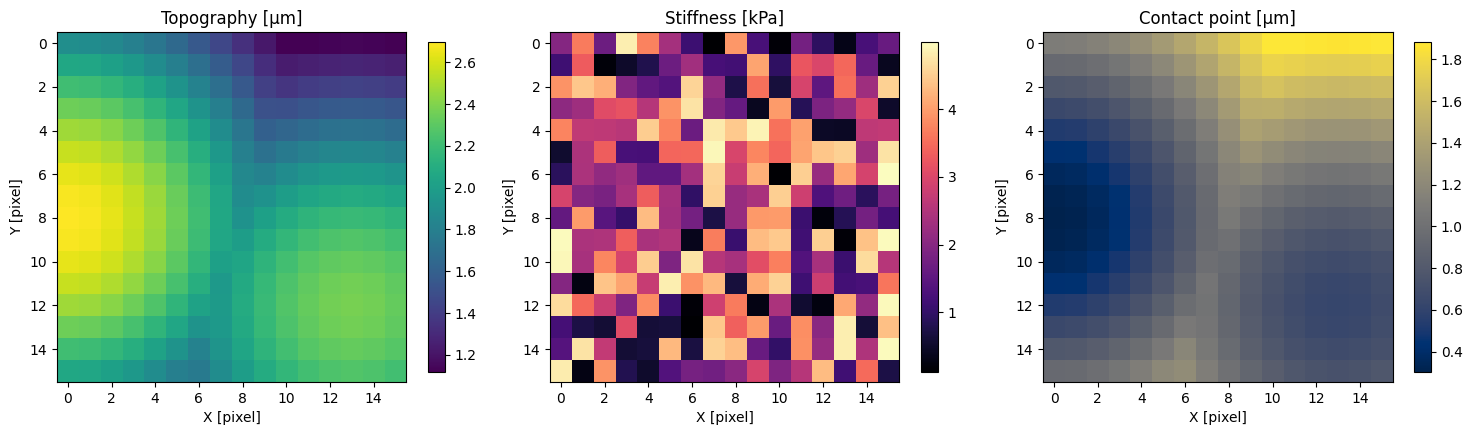

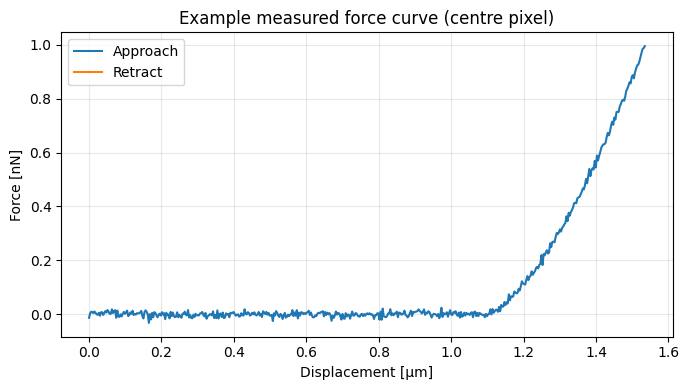

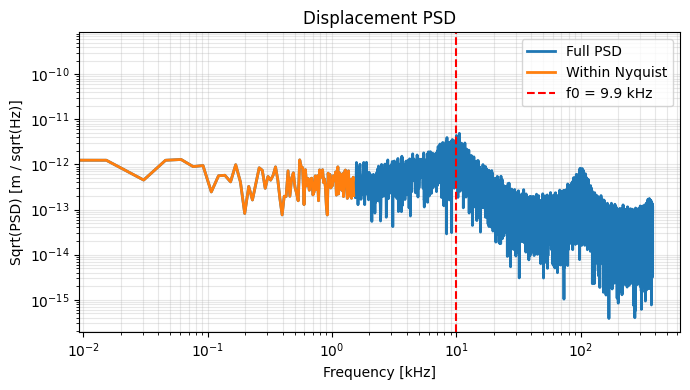

In [10]:
# We use the simulator to generate data and visualise it with the functions
# defined above.
rng = np.random.default_rng(SEED)

example_substrate_stiffness_range_pa = (0.1e3, 5e3)
example_feature_stiffness_range_pa = (0.1e3, 5e3)
example_nx = 16
example_ny = 16

example_stiffness_min_pa = min(example_substrate_stiffness_range_pa[0],
                               example_feature_stiffness_range_pa[0])
example_stiffness_max_pa = max(example_substrate_stiffness_range_pa[1],
                               example_feature_stiffness_range_pa[1])

cantilever = AFMCantilever(k=0.178, f0=10e3, Q=100.0, T=300.0)
contact_model = HertzContact(R=1e-6, nu=0.5, alpha=18.0)
sample_generator = SampleGenerator(
    substrate_stiffness_range_pa=example_substrate_stiffness_range_pa,
    feature_stiffness_range_pa=example_feature_stiffness_range_pa,
    height_range_m=dataset_config.height_range_m
)
simulator = AFMSimulator(
    cantilever=cantilever,
    contact_model=contact_model,
    sample_generator=sample_generator,
    config=simulation_config,
)

print(f"Approach points = {simulator.n_points_approach}")
print(f"Setpoint force range = \
{min(simulation_config.setpoint_force_n_range) * 1e9:.2f} - \
{max(simulation_config.setpoint_force_n_range) * 1e9:.2f} nN")

example_topography_m, example_stiffness_pa = (
    sample_generator.create_topography(
        size=(example_nx, example_ny),
        pixel_size_m=simulation_config.pixel_size_m,
        topography_type="gaussian_features",
        rng=rng,
    )
)

example_output = simulator.simulate_force_map(
    stiffness_map_pa=example_stiffness_pa,
    topography_map_m=example_topography_m,
    include_thermal_noise=simulation_config.include_thermal_noise,
    rng=rng,
)

plot_maps(
    example_topography_m, 
    example_stiffness_pa, 
    example_output["contact_point_map_m"]
)

center_row = 0
center_col = 0
plot_force_curve(
    example_output["displacement_curves_m"][center_row, center_col],
    example_output["measured_force_curves_n"][center_row, center_col],
    retract_start_index= \
      int(example_output["retract_start_indices"][center_row, center_col]),
    valid_length=int(example_output["curve_lengths"][center_row, center_col]),
    title="Example measured force curve (centre pixel)",
)

reference_points = max(simulator.n_points_approach * 2, 64)
if simulation_config.noise_type == "rms":
    frequency_hz, spectral_density_m2_per_hz = cantilever.get_noise_psd(
        n_points=reference_points,
        sampling_frequency_hz=cantilever.f0*10,
        noise_type="theoretical",
        experimental_path=simulation_config.experimental_noise_path,
    )

else:
    frequency_hz, spectral_density_m2_per_hz = cantilever.get_noise_psd(
        n_points=reference_points,
        sampling_frequency_hz=cantilever.f0*10,
        noise_type=simulation_config.noise_type,
        experimental_path=simulation_config.experimental_noise_path,
    )
plot_psd(
    frequency_hz,
    spectral_density_m2_per_hz,
    cantilever,
    sampling_frequency=simulation_config.sampling_frequency_hz,
)
